# Finite difference heat solver - FFF thin wall

Generates stand-in thermal data while the FEA files are pending.

**Problem.** A 1D slice through the build direction (z) of a printed wall.
A fresh layer at nozzle temperature is deposited on top of previously
printed material. Heat flows down into the wall toward the heated bed and
out of the top surface into the air.

$$\rho c_p \frac{\partial T}{\partial t} = k \frac{\partial^2 T}{\partial z^2}$$

Boundary conditions:
- bottom (z = 0): fixed at bed temperature
- top (z = H): convection to ambient, $-k \,\partial T/\partial z = h (T - T_\infty)$

The quantity of interest is the temperature at the **interface** between the
new layer and the one below it, and how long it stays above the glass
transition $T_g$ — that is what controls interlayer bond strength.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("data", exist_ok=True)

## Material and process parameters

PLA values. Swap these for the lab's actual filament when known.

In [5]:
# material
k    = 0.13     # thermal conductivity, W/(m K)
rho  = 1240.0   # density, kg/m^3
cp   = 1800.0   # specific heat, J/(kg K)
Tg   = 60.0     # glass transition, degC

# geometry
H    = 5e-3     # wall height modelled, m
LH   = 0.2e-3   # layer height (thickness of the fresh layer), m
nz   = 251      # grid points

# process / boundary
T_nozzle = 210.0   # fresh layer deposition temperature, degC
T_prev   = 40.0    # temperature of previously printed material, degC
T_bed    = 60.0    # build plate, degC
T_inf    = 25.0    # ambient air, degC
h        = 50.0    # convection coefficient, W/(m^2 K)

t_end = 20.0       # simulated time, s

alpha = k / (rho * cp)   # thermal diffusivity, m^2/s
print(f"alpha = {alpha:.3e} m^2/s")

alpha = 5.824e-08 m^2/s


## The solver

Explicit forward-time, centre-space. The scheme is only stable when the
Fourier number

$$\mathrm{Fo} = \frac{\alpha \, \Delta t}{\Delta z^2} \le \tfrac{1}{2}$$

so the time step is chosen from the grid spacing rather than set by hand.
`safety = 0.4` keeps a margin below the limit.

The convective top boundary uses a ghost node, which is why the last
node's update has a factor of 2.

In [8]:
def solve_wall(k=k, rho=rho, cp=cp,
               H=H, LH=LH, nz=nz,
               T_nozzle=T_nozzle, T_prev=T_prev, T_bed=T_bed, T_inf=T_inf,
               h=h, t_end=t_end, n_save=400, safety=0.4):
    """Solve 1D transient conduction through the build direction.

    Returns
    -------
    z  : (nz,)        grid positions, m
    ts : (n_save+,)   saved times, s
    Ts : (n_t, nz)    temperature field, degC
    """
    alpha = k / (rho * cp)
    dz = H / (nz - 1)
    dt = safety * dz**2 / alpha          # stability-limited step
    nt = int(t_end / dt)

    z = np.linspace(0.0, H, nz)

    # initial condition: fresh hot layer on top of cooler printed material
    T = np.where(z >= H - LH, T_nozzle, T_prev)
    T[0] = T_bed

    save_every = max(1, nt // n_save)
    ts, Ts = [], []

    for n in range(nt + 1):
        if n % save_every == 0:
            ts.append(n * dt)
            Ts.append(T.copy())

        Tn = T
        Tnew = Tn.copy()

        # interior nodes
        Tnew[1:-1] = Tn[1:-1] + alpha*dt/dz**2 * (Tn[2:] - 2*Tn[1:-1] + Tn[:-2])

        # bottom: fixed bed temperature
        Tnew[0] = T_bed

        # top: convection to ambient (ghost node)
        Tnew[-1] = Tn[-1] + 2*alpha*dt/dz**2 * (
            Tn[-2] - Tn[-1] - dz*h/k * (Tn[-1] - T_inf)
        )

        T = Tnew

    return z, np.array(ts), np.array(Ts)


def time_above(ts, T_series, T_thresh):
    """Seconds the series spends above a threshold."""
    mask = (T_series > T_thresh).astype(float)
    integrate = getattr(np, "trapezoid", None) or np.trapz
    return float(integrate(mask, ts))

## Run it

In [9]:
z, ts, Ts = solve_wall()

i_iface = np.argmin(np.abs(z - (H - LH)))   # new layer / old layer interface
T_iface = Ts[:, i_iface]

print(f"grid: {Ts.shape[1]} points, {Ts.shape[0]} saved time steps")
print(f"interface temperature at t = 0, 0.5, 1, 2, 5 s:")
print(np.interp([0, 0.5, 1, 2, 5], ts, T_iface).round(1))
print(f"time above Tg = {time_above(ts, T_iface, Tg):.2f} s")

grid: 251 points, 405 saved time steps
interface temperature at t = 0, 0.5, 1, 2, 5 s:
[210.  117.  102.   85.1  65.6]
time above Tg = 6.95 s


## Plots

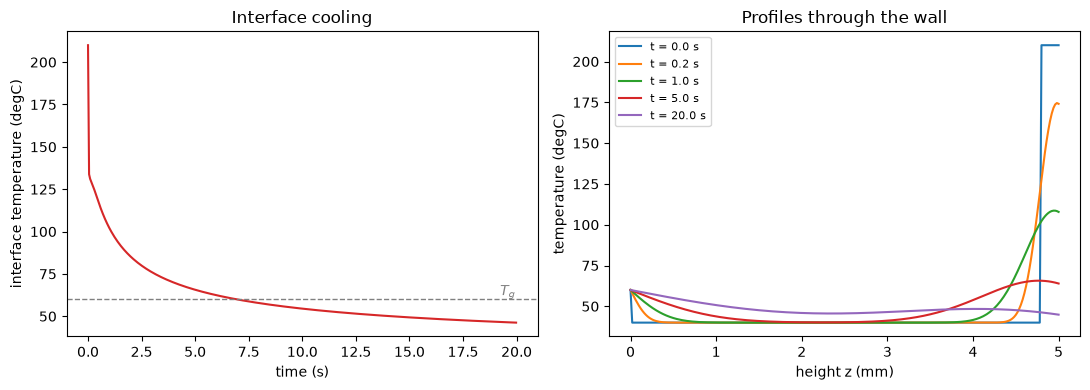

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# interface temperature over time
ax[0].plot(ts, T_iface, color="tab:red")
ax[0].axhline(Tg, ls="--", color="grey", lw=1)
ax[0].text(ts[-1], Tg + 2, "$T_g$", ha="right", color="grey")
ax[0].set_xlabel("time (s)")
ax[0].set_ylabel("interface temperature (degC)")
ax[0].set_title("Interface cooling")

# temperature profiles through the wall at several times
for t_want in [0.0, 0.2, 1.0, 5.0, 20.0]:
    j = np.argmin(np.abs(ts - t_want))
    ax[1].plot(z*1e3, Ts[j], label=f"t = {ts[j]:.1f} s")
ax[1].set_xlabel("height z (mm)")
ax[1].set_ylabel("temperature (degC)")
ax[1].set_title("Profiles through the wall")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Sanity checks

Worth running these before trusting any of the output.

1. **Grid independence.** Double `nz`. If the answer moves much, the grid is too coarse.
2. **Energy direction.** Everything should cool monotonically toward the bed/ambient range — no overshoot above `T_nozzle`.
3. **Stability.** Raising `safety` above 0.5 should make the solution blow up. If it doesn't, the time step isn't actually being set by the grid.

In [11]:
# 1. grid independence
for n in [126, 251, 501]:
    z2, t2, T2 = solve_wall(nz=n)
    i2 = np.argmin(np.abs(z2 - (H - LH)))
    print(f"nz = {n:4d}   t_above_Tg = {time_above(t2, T2[:, i2], Tg):.3f} s")

# 2. no overshoot
print(f"\nmax temperature anywhere: {Ts.max():.1f} degC (should be <= {T_nozzle})")

nz =  126   t_above_Tg = 7.406 s
nz =  251   t_above_Tg = 6.947 s
nz =  501   t_above_Tg = 6.700 s

max temperature anywhere: 210.0 degC (should be <= 210.0)


## Parameter sweep

This is the data the stage-2 PINN would learn from — one solve per
combination of print settings.

In [12]:
records = []
fields = []

for T_noz in [190.0, 210.0, 230.0]:
    for lh in [0.1e-3, 0.2e-3, 0.3e-3]:
        for hh in [25.0, 50.0, 100.0]:
            z_, t_, T_ = solve_wall(T_nozzle=T_noz, LH=lh, h=hh)
            ii = np.argmin(np.abs(z_ - (H - lh)))
            records.append(dict(T_nozzle=T_noz, layer_height=lh, h=hh,
                                t_above_Tg=time_above(t_, T_[:, ii], Tg)))
            fields.append(T_)

print(f"{len(records)} runs")
for r in records[:9]:
    print(f"T_noz={r['T_nozzle']:.0f}  LH={r['layer_height']*1e3:.1f}mm  "
          f"h={r['h']:.0f}  ->  t_above_Tg = {r['t_above_Tg']:.2f} s")

27 runs
T_noz=190  LH=0.1mm  h=25  ->  t_above_Tg = 2.65 s
T_noz=190  LH=0.1mm  h=50  ->  t_above_Tg = 2.10 s
T_noz=190  LH=0.1mm  h=100  ->  t_above_Tg = 1.56 s
T_noz=190  LH=0.2mm  h=25  ->  t_above_Tg = 7.84 s
T_noz=190  LH=0.2mm  h=50  ->  t_above_Tg = 5.81 s
T_noz=190  LH=0.2mm  h=100  ->  t_above_Tg = 3.98 s
T_noz=190  LH=0.3mm  h=25  ->  t_above_Tg = 14.61 s
T_noz=190  LH=0.3mm  h=50  ->  t_above_Tg = 10.31 s
T_noz=190  LH=0.3mm  h=100  ->  t_above_Tg = 6.85 s


## Save

`baseline.npz` is what `pinn_thermal.ipynb` loads.

In [13]:
np.savez("data/baseline.npz",
         z=z, t=ts, T=Ts,
         k=k, rho=rho, cp=cp, alpha=alpha,
         H=H, LH=LH, T_nozzle=T_nozzle, T_prev=T_prev,
         T_bed=T_bed, T_inf=T_inf, h=h, Tg=Tg)

np.savez("data/sweep.npz",
         params=np.array([[r["T_nozzle"], r["layer_height"], r["h"]] for r in records]),
         t_above=np.array([r["t_above_Tg"] for r in records]),
         fields=np.array(fields), z=z, t=ts)

print("saved data/baseline.npz and data/sweep.npz")

saved data/baseline.npz and data/sweep.npz
